# Baseline and data exploration: CIFAR-10

CIFAR-10 has 50,000 training and 10,000 test colour photos in 10 classes (airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck), 5,000 training and 1,000 test images per class. The photos are 32 x 32; for the models they are resized to 28 x 28, so that every model is exactly the same on all four datasets (the images shown below are the originals). It is much harder than MNIST or Fashion-MNIST: the objects change in pose, colour, size and background, and several classes look alike (cat and dog, automobile and truck).

This notebook looks at the data itself (classes, examples, how we split it across 10 clients and how non-IID each split is) and at the classical CNN trained with FedAvg, which is the reference for every hybrid result. The figures are saved to `results/plots/cifar10`. The model results are in `plot_results_cifar10.ipynb`.

In [1]:
import io
import os
import sys
import contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator

sys.path.insert(0, os.path.abspath(".."))
from data import load_dataset, get_labels, iid_partition, dirichlet_partition, compute_emd_proxy

%matplotlib inline

In [2]:
DATASET    = "cifar10"
TABLES_DIR = os.path.join("../results/tables", "cifar10")
PLOTS_DIR  = os.path.join("../results/plots", "cifar10")
CLASSES    = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

SPLITS = {"IID": ("iid", None), "Dirichlet α=0.5": ("dirichlet", 0.5), "Dirichlet α=0.1": ("dirichlet", 0.1)}
SKEW_COLORS = {"IID": "#86b6ef", "Dirichlet α=0.5": "#2a78d6", "Dirichlet α=0.1": "#104281"}
BLUES = LinearSegmentedColormap.from_list("blues", ["#f3f7fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
INK = "#52514e"

os.makedirs(PLOTS_DIR, exist_ok=True)

## 1. The dataset

Number of images per class in the training and test sets.

In [3]:
train, test = load_dataset(DATASET)
y_train, y_test = get_labels(train), get_labels(test)
images = train.data   # raw pixels of the original 32 x 32 photos, 0 to 255

counts = pd.DataFrame({
    "class": CLASSES,
    "train images": np.bincount(y_train, minlength=len(CLASSES)),
    "test images": np.bincount(y_test, minlength=len(CLASSES)),
})
counts["train share (%)"] = (counts["train images"] / len(y_train) * 100).round(1)
counts["test share (%)"] = (counts["test images"] / len(y_test) * 100).round(1)
print(f"{len(y_train):,} training and {len(y_test):,} test images, image shape {tuple(images.shape[1:])}, {len(CLASSES)} classes")
counts

[data] cifar10: 50000 train / 10000 test
50,000 training and 10,000 test images, image shape (32, 32, 3), 10 classes


,class,train images,test images,train share (%),test share (%)
0,airplane,5000,1000,10.0,10.0
1,automobile,5000,1000,10.0,10.0
2,bird,5000,1000,10.0,10.0
3,cat,5000,1000,10.0,10.0
4,deer,5000,1000,10.0,10.0
5,dog,5000,1000,10.0,10.0
6,frog,5000,1000,10.0,10.0
7,horse,5000,1000,10.0,10.0
8,ship,5000,1000,10.0,10.0
9,truck,5000,1000,10.0,10.0


Class balance. The dashed line is an equal share for every class.

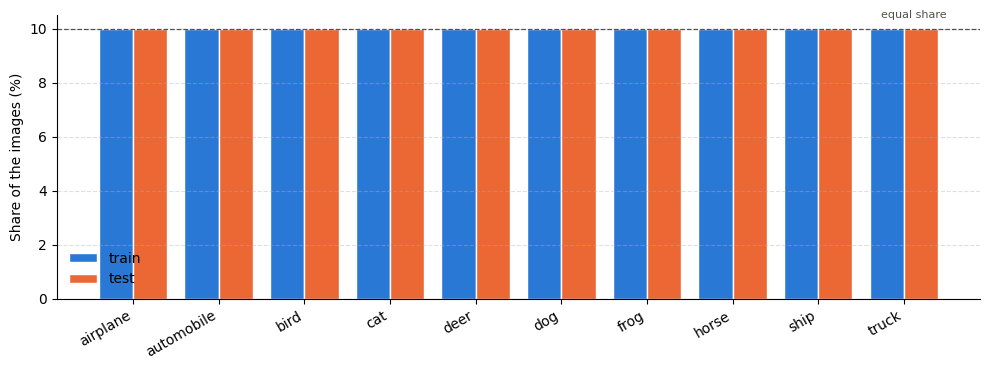

Saved: ../results/plots\cifar10\class_balance.png


In [4]:
x = np.arange(len(CLASSES))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(x - 0.2, counts["train share (%)"], 0.4, color="#2a78d6", edgecolor="white", label="train")
ax.bar(x + 0.2, counts["test share (%)"], 0.4, color="#eb6834", edgecolor="white", label="test")
ax.axhline(100 / len(CLASSES), color=INK, ls="--", lw=0.9)
ax.text(len(CLASSES) - 0.5, 100 / len(CLASSES) + 0.4, "equal share", ha="right", fontsize=8, color=INK)
ax.set_xticks(x)
ax.set_xticklabels(CLASSES, rotation=30, ha="right")
ax.set_ylabel("Share of the images (%)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", ls="--", alpha=0.4)
ax.legend(frameon=False)
fig.tight_layout()

out = os.path.join(PLOTS_DIR, "class_balance.png")
fig.savefig(out, dpi=200)
plt.show()
print(f"Saved: {out}")

Eight random training images of every class:

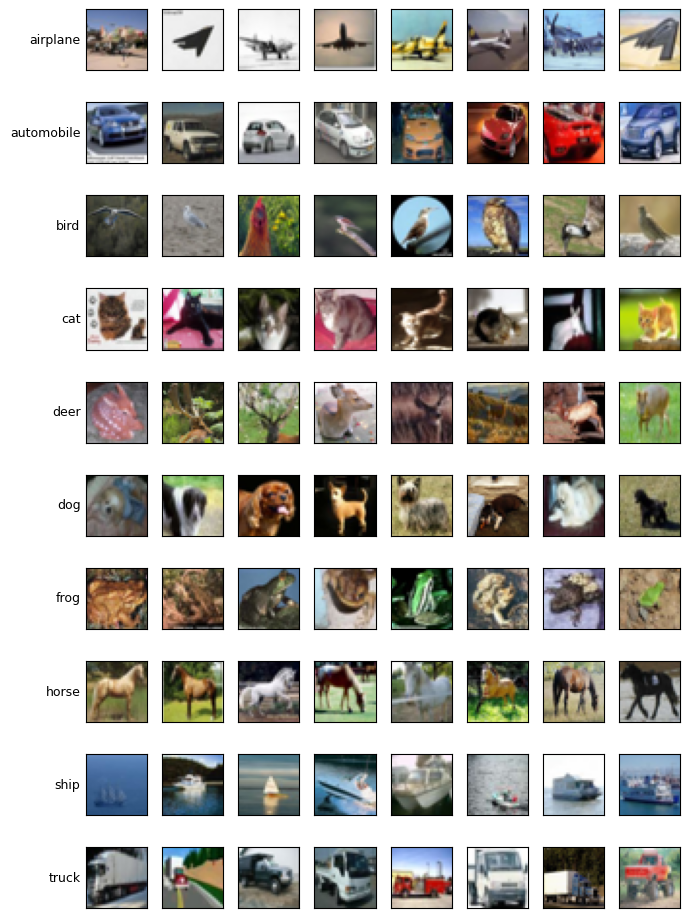

Saved: ../results/plots\cifar10\samples.png


In [5]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(len(CLASSES), 8, figsize=(7, len(CLASSES) * 0.95))
for c, name in enumerate(CLASSES):
    picks = rng.choice(np.where(y_train == c)[0], 8, replace=False)
    for j, i in enumerate(picks):
        axes[c, j].imshow(images[i], cmap="gray" if images.ndim == 3 else None)
        axes[c, j].set_xticks([])
        axes[c, j].set_yticks([])
    axes[c, 0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
fig.tight_layout()

out = os.path.join(PLOTS_DIR, "samples.png")
fig.savefig(out, dpi=200)
plt.show()
print(f"Saved: {out}")

The average image of every class, and the pixel statistics (pixels scaled to 0 to 1 here; the models see them normalised to −1 to 1):

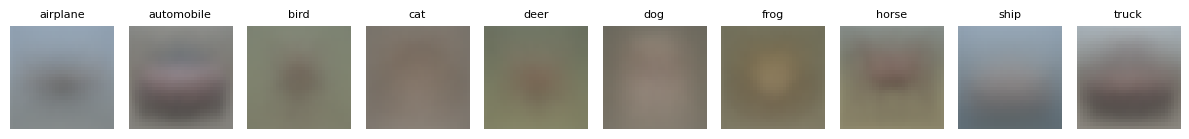

Saved: ../results/plots\cifar10\class_means.png
pixel mean per channel: [0.491 0.482 0.447] | pixel std per channel: [0.247 0.243 0.262]


In [6]:
fig, axes = plt.subplots(1, len(CLASSES), figsize=(len(CLASSES) * 1.2, 1.7))
for c, name in enumerate(CLASSES):
    mean_image = images[y_train == c].mean(axis=0)
    axes[c].imshow(mean_image.astype(np.uint8), cmap="gray" if images.ndim == 3 else None)
    axes[c].set_title(name, fontsize=8)
    axes[c].axis("off")
fig.tight_layout()

out = os.path.join(PLOTS_DIR, "class_means.png")
fig.savefig(out, dpi=200)
plt.show()
print(f"Saved: {out}")

pixels = images.reshape(len(images), -1, 1 if images.ndim == 3 else 3) / 255
print("pixel mean per channel:", pixels.mean(axis=(0, 1)).round(3), "| pixel std per channel:", pixels.std(axis=(0, 1)).round(3))

## 2. How the data is split across 10 clients

Each row is one client (its number of images in brackets) and each column one class; the colour is the share of that client's images that belong to the class. With IID every client has every class; with Dirichlet α = 0.1 most clients hold only one to three classes. The EMD is the measured non-IID level (0 = all clients have the same class mix, 2 = no two clients share a class). Seed 42.

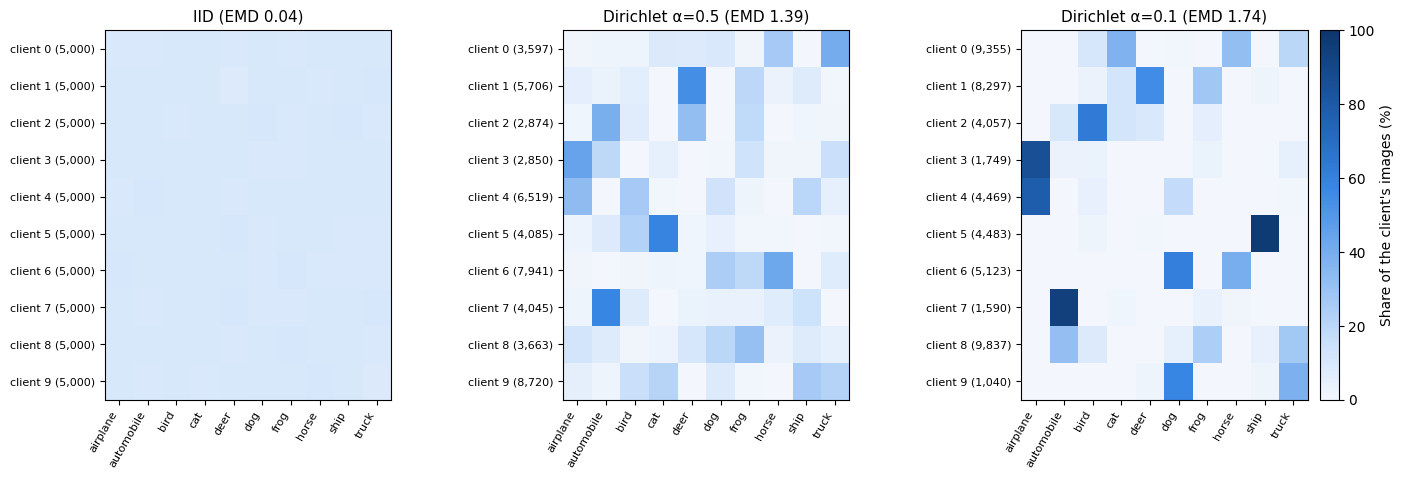

Saved: ../results/plots\cifar10\client_splits.png


In [7]:
splits = {}
for name, (kind, alpha) in SPLITS.items():
    with contextlib.redirect_stdout(io.StringIO()):   # the partition functions print their own summary
        if kind == "iid":
            idx = iid_partition(train, n_clients=10, seed=42)
        else:
            idx = dirichlet_partition(train, n_clients=10, alpha=alpha, seed=42)
        emd = compute_emd_proxy(idx, train)
    per_client = np.array([np.bincount(y_train[idx[k]], minlength=len(CLASSES)) for k in range(10)])
    splits[name] = (per_client, emd)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"wspace": 0.6})
for ax, (name, (per_client, emd)) in zip(axes, splits.items()):
    share = per_client / per_client.sum(axis=1, keepdims=True) * 100
    im = ax.imshow(share, cmap=BLUES, vmin=0, vmax=100, aspect="auto")
    ax.set_title(f"{name} (EMD {emd:.2f})", fontsize=11)
    ax.set_xticks(range(len(CLASSES)))
    ax.set_xticklabels(CLASSES, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(10))
    ax.set_yticklabels([f"client {k} ({n:,})" for k, n in enumerate(per_client.sum(axis=1))], fontsize=8)
cb = fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01)
cb.set_label("Share of the client's images (%)")

out = os.path.join(PLOTS_DIR, "client_splits.png")
fig.savefig(out, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved: {out}")

Measured EMD for different Dirichlet α (mean ± std over seeds 42 to 49). Smaller α gives more skew; the curve shows how α maps to the measured non-IID level on this dataset.

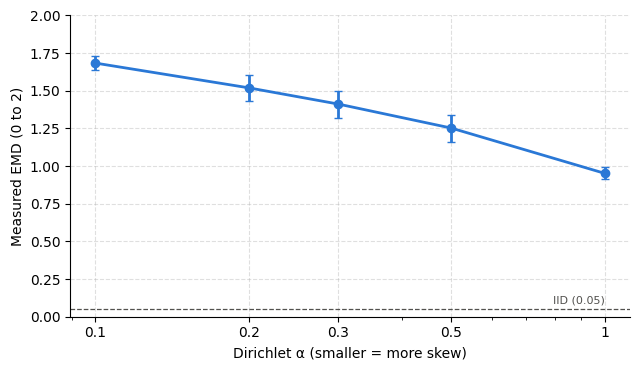

Saved: ../results/plots\cifar10\emd_vs_alpha.png


,mean,std
alpha,,
1.0,0.952,0.040
0.5,1.253,0.089
0.3,1.412,0.090
0.2,1.520,0.085
0.1,1.684,0.046


In [8]:
alphas = [1.0, 0.5, 0.3, 0.2, 0.1]
rows = []
for alpha in alphas:
    for seed in range(42, 50):
        with contextlib.redirect_stdout(io.StringIO()):
            emd = compute_emd_proxy(dirichlet_partition(train, n_clients=10, alpha=alpha, seed=seed), train)
        rows.append({"alpha": alpha, "seed": seed, "emd": emd})
with contextlib.redirect_stdout(io.StringIO()):
    iid_emd = np.mean([compute_emd_proxy(iid_partition(train, n_clients=10, seed=s), train) for s in range(42, 50)])
emd_table = pd.DataFrame(rows).groupby("alpha")["emd"].agg(["mean", "std"]).sort_index(ascending=False)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.errorbar(emd_table.index, emd_table["mean"], yerr=emd_table["std"], color="#2a78d6", marker="o", lw=2, capsize=3)
ax.axhline(iid_emd, color=INK, ls="--", lw=0.9)
ax.text(1.0, iid_emd + 0.04, f"IID ({iid_emd:.2f})", ha="right", fontsize=8, color=INK)
ax.set_xscale("log")
ax.set_xticks(alphas)
ax.set_xticklabels([f"{a:g}" for a in alphas])
ax.set_xlabel("Dirichlet α (smaller = more skew)")
ax.set_ylabel("Measured EMD (0 to 2)")
ax.set_ylim(0, 2)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(True, ls="--", alpha=0.4)
fig.tight_layout()

out = os.path.join(PLOTS_DIR, "emd_vs_alpha.png")
fig.savefig(out, dpi=200)
plt.show()
print(f"Saved: {out}")
emd_table.round(3)

## 3. Classical FedAvg baseline

The classical CNN (106,154 parameters with 3 colour channels) trained with FedAvg on the same splits as the hybrid model: 10 clients, 20 rounds, 1 local epoch, batch size 32, learning rate 0.001. Mean over seeds, the shaded band is ±1 std. Splits that have not been run yet are skipped.

CIFAR-10 is hard for a model this small trained for only 20 short rounds: even this classical CNN stays far below its accuracy on the other datasets. This is the reference to keep in mind when reading the hybrid results, which are lower still.

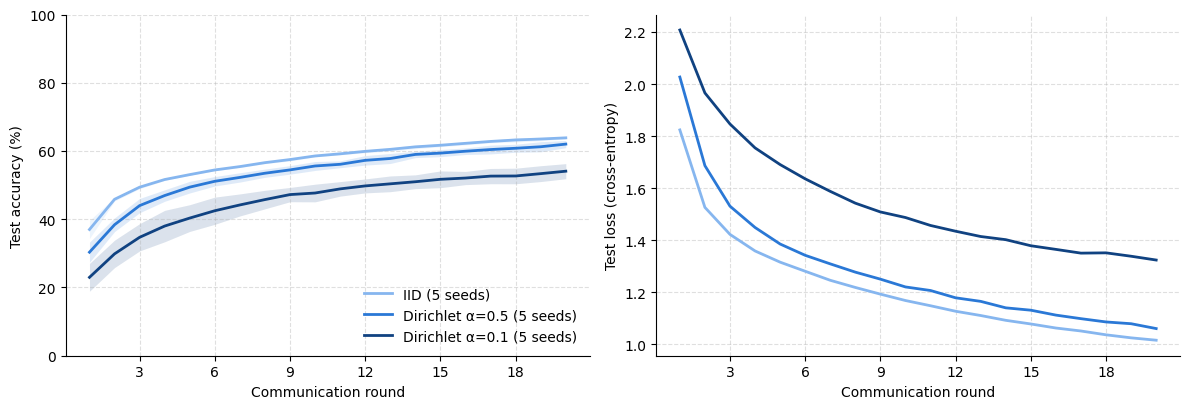

Saved: ../results/plots\cifar10\classical_baseline.png
Drop from IID to the strongest skew: 10.16 points


,split,seeds,EMD,last-5 accuracy,std
0,IID,5,0.05,63.13,0.48
1,Dirichlet α=0.5,5,1.28,60.88,1.30
2,Dirichlet α=0.1,5,1.69,52.97,2.41


In [9]:
curves, table = {}, []
for name, (kind, alpha) in SPLITS.items():
    tag = "iid_a0.5" if kind == "iid" else f"dirichlet_a{alpha}"
    found = []
    for seed in range(42, 50):
        path = os.path.join(TABLES_DIR, f"classical_{tag}_c10_e1_lr0.001_s{seed}.csv")
        if os.path.exists(path):
            df = pd.read_csv(path)
            if len(df) >= 20:
                found.append(df)
    if not found:
        continue
    acc = np.array([df["accuracy"].values[:20] * 100 for df in found])
    loss = np.array([df["loss"].values[:20] for df in found])
    curves[name] = (acc, loss)
    last5 = acc[:, -5:].mean(axis=1)
    table.append({"split": name, "seeds": len(found), "EMD": np.mean([df["emd"].iloc[0] for df in found]),
                  "last-5 accuracy": last5.mean(), "std": last5.std(ddof=1) if len(found) > 1 else 0.0})

fig, (ax_acc, ax_loss) = plt.subplots(1, 2, figsize=(12, 4.2))
rounds = np.arange(1, 21)
for name, (acc, loss) in curves.items():
    ax_acc.plot(rounds, acc.mean(axis=0), color=SKEW_COLORS[name], lw=2, label=f"{name} ({len(acc)} seeds)")
    ax_acc.fill_between(rounds, acc.mean(axis=0) - acc.std(axis=0), acc.mean(axis=0) + acc.std(axis=0), color=SKEW_COLORS[name], alpha=0.15, lw=0)
    ax_loss.plot(rounds, loss.mean(axis=0), color=SKEW_COLORS[name], lw=2, label=name)
ax_acc.set_ylim(0, 100)
ax_acc.set_ylabel("Test accuracy (%)")
ax_loss.set_ylabel("Test loss (cross-entropy)")
for ax in (ax_acc, ax_loss):
    ax.set_xlabel("Communication round")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(True, ls="--", alpha=0.4)
ax_acc.legend(frameon=False, loc="lower right")
fig.tight_layout()

out = os.path.join(PLOTS_DIR, "classical_baseline.png")
fig.savefig(out, dpi=200)
plt.show()
print(f"Saved: {out}")

table = pd.DataFrame(table)
if len(table) > 1:
    print(f"Drop from IID to the strongest skew: {table['last-5 accuracy'].iloc[0] - table['last-5 accuracy'].iloc[-1]:.2f} points")
table.round(2)